# Tutorial: Processing Raw LIDAR Data into 3D Coordinate Points

LIDAR (Light Detection and Ranging) sensors typically measure the time of flight of laser pulses to determine the distance (range) to an object, along with the horizontal (azimuth) and vertical (elevation) angles of the laser emitter.

In this tutorial, we will:
1. **Generate Synthetic Raw LIDAR Data**: Simulate raw sensor outputs (Range, Azimuth, Elevation, and Intensity).
2. **Convert Raw Data to 3D Coordinates**: Convert spherical coordinates $(r, \theta, \phi)$ into Cartesian coordinates $(X, Y, Z)$.
3. **Visualize the 3D Point Cloud**: Use `matplotlib` to render the points in a 3D scatter plot.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from notebook.services.config import ConfigManager

# Set random seed for reproducibility
np.random.seed(42)

print("Libraries successfully imported!")

Libraries successfully imported!


## Step 1: Generate Synthetic Raw LIDAR Data

Raw LIDAR data often consists of:
- **Azimuth (Horizontal Angle, $\theta$):** Typically ranges from $0^\circ$ to $360^\circ$ (or $-\pi$ to $\pi$ radians).
- **Elevation (Vertical Angle, $\phi$):** Typically ranges from $-15^\circ$ to $15^\circ$ depending on the sensor's vertical field of view.
- **Distance (Range, $r$):** The measured distance to the target.
- **Intensity:** The strength of the returning laser pulse.

In [ ]:
def generate_synthetic_lidar(num_points=5000):
    # Simulate a ground plane and a simple object (like a wall or box)
    # Horizontal angles (azimuth) from -180 to 180 degrees
    azimuth = np.random.uniform(-np.pi, np.pi, num_points)

    # Vertical angles (elevation) from -15 to 15 degrees
    elevation = np.random.uniform(-np.radians(15), np.radians(15), num_points)

    # Define a default range (with some noise)
    range_m = np.random.uniform(10.0, 20.0, num_points)

    # Let's simulate a flat ground plane where points hitting the ground have a predictable height
    # and some points hit a vertical wall directly in front of the sensor (azimuth around 0)
    for i in range(num_points):
        # Ground plane simulation: Z = -1.5 meters
        # Since Z = range * sin(elevation), range = -1.5 / sin(elevation)
        if elevation[i] < -np.radians(5):
            range_m[i] = -1.5 / np.sin(elevation[i]) + np.random.normal(0, 0.02)

        # Wall simulation: A wall 8 meters ahead at azimuth -30 to +30 degrees
        elif abs(azimuth[i]) < np.radians(30):
            # X = range * cos(elevation) * cos(azimuth) -> range = 8 / (cos(elevation) * cos(azimuth))
            range_m[i] = 8.0 / (np.cos(elevation[i]) * np.cos(azimuth[i])) + np.random.normal(0, 0.02)

    # Simulate intensity based on distance (closer objects return stronger signals)
    intensity = np.clip(255 / (range_m ** 0.5) + np.random.normal(0, 5, num_points), 0, 255)

    # Build DataFrame representing raw sensor output
    raw_df = pd.DataFrame({
        'azimuth_rad': azimuth,
        'elevation_rad': elevation,
        'distance_m': range_m,
        'intensity': intensity
    })
    return raw_df

raw_lidar_data = generate_synthetic_lidar()
display(raw_lidar_data.head())

,azimuth_rad,elevation_rad,distance_m,intensity
0,-0.788288,-0.055692,13.736408,64.939857
1,2.831922,-0.013909,13.329121,73.544457
2,1.457661,0.185641,11.761539,81.780727
3,0.619890,-0.083774,16.072667,69.193888
4,-2.161299,0.193548,14.766242,68.869080


## Step 2: Convert Raw Data to 3D Coordinates (Spherical to Cartesian)

We convert spherical coordinates $(r, \theta, \phi)$ to Cartesian $(X, Y, Z)$ using standard trigonometry:

$$
X = r \cdot \cos(\phi) \cdot \cos(\theta)
$$
$$
Y = r \cdot \cos(\phi) \cdot \sin(\theta)
$$
$$
Z = r \cdot \sin(\phi)
$$

Where:
- $r$ is `distance_m`
- $\theta$ is `azimuth_rad`
- $\phi$ is `elevation_rad`

In [ ]:
def raw_to_cartesian(df):
    r = df['distance_m']
    theta = df['azimuth_rad']
    phi = df['elevation_rad']

    df['X'] = r * np.cos(phi) * np.cos(theta)
    df['Y'] = r * np.cos(phi) * np.sin(theta)
    df['Z'] = r * np.sin(phi)
    return df

processed_lidar_data = raw_to_cartesian(raw_lidar_data)
display(processed_lidar_data[['distance_m', 'azimuth_rad', 'elevation_rad', 'X', 'Y', 'Z', 'intensity']].head())

,distance_m,azimuth_rad,elevation_rad,X,Y,Z,intensity
0,13.736408,-0.788288,-0.055692,9.669985,-9.726030,-0.764617,64.939857
1,13.329121,2.831922,-0.013909,-12.693878,4.061596,-0.185390,73.544457
2,11.761539,1.457661,0.185641,1.304995,11.485555,2.170900,81.780727
3,16.072667,0.619890,-0.083774,13.036350,9.304594,-1.344889,69.193888
4,14.766242,-2.161299,0.193548,-8.068011,-12.036716,2.840168,68.869080


## Step 3: Visualize the Final 3D Point Cloud

Now, we'll plot the processed $(X, Y, Z)$ points using Matplotlib's 3D projection, coloring the points by their intensity values.

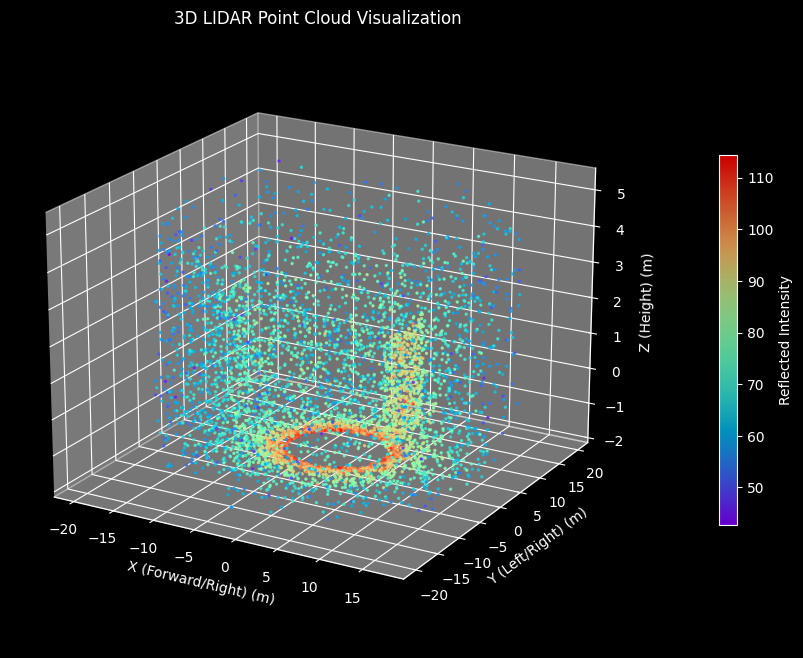

In [ ]:
fig = plt.figure(figsize=(12, 8))
ax = fig.add_subplot(111, projection='3d')


# Extract coordinates
x = processed_lidar_data['X']
y = processed_lidar_data['Y']
z = processed_lidar_data['Z']
colors = processed_lidar_data['intensity']

# Create 3D Scatter plot
scatter = ax.scatter(x, y, z, c=colors, cmap='rainbow', s=2, alpha=0.8)

# Add details and labels
ax.set_title('3D LIDAR Point Cloud Visualization')
ax.set_xlabel('X (Forward/Right) (m)')
ax.set_ylabel('Y (Left/Right) (m)')
ax.set_zlabel('Z (Height) (m)')

# Adjust viewport angle for better perspective
ax.view_init(elev=20, azim=-60)

# Add a colorbar indicating pulse intensity
cbar = fig.colorbar(scatter, ax=ax, pad=0.1, shrink=0.6)
cbar.set_label('Reflected Intensity')
#plt.style.use('dark_background')
#plt.style.use('light_background')

plt.show()